## Imports

In [1]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
%matplotlib inline

## Rosenbrock Function and Gradient

In [2]:
a = 1
b = 100

def rosenbrock(x):
    return (a - x[0]) ** 2 + b * (x[1] - x[0] ** 2) ** 2

def grad_rosenbrock(x):
    return np.array([-2.0 * (a - x[0]) - 4.0 * b * x[0] * (x[1] - x[0] ** 2), 
                     2.0 * b * (x[1] - x[0] ** 2)])

## Line Search and Gradient Descent

In [3]:
beta = 1e-4
p = 0.5
epsilon_fixed = 1e-4
epsilon_adaptive = 1e-6

def linesearch(x, d):
    alpha = 1
    b = rosenbrock(x)
    while rosenbrock(x - alpha * d) >  b - alpha * beta * d.dot(d):
        alpha *= p
    return alpha

def grad_step(x, use_linesearch=True):
    d = grad_rosenbrock(x)
    if use_linesearch:
        alpha = linesearch(x, d)
    else:
        alpha = 1e-3
    return x - alpha * d

def optimize(x0):
    x_line, x_noline = [x0], [x0]
    x_l, x_nl = x0, x0
    
    while np.linalg.norm(grad_rosenbrock(x_l)) > epsilon_adaptive and len(x_line) < 100000:
        x_l = grad_step(x_l, use_linesearch=True)
        x_line.append(x_l)
        
    while np.linalg.norm(grad_rosenbrock(x_nl)) > epsilon_fixed and len(x_noline) < 200000:
        x_nl = grad_step(x_nl, use_linesearch=False)
        x_noline.append(x_nl)
    
    return x_line, x_noline

## Plot Iterations

In [4]:
def plot_optimization_paths(f, paths, labels, a=1, b=100, subsample_rate=1000):
    """
    Plots the level curves of the Rosenbrock function and overlays high-contrast optimization paths.
    Uses a clean, pure white background canvas with zero background grid lines.
    """
    # 1. Create a dense grid around the minimum
    x = np.linspace(-2.0, 2.0, 400)
    y = np.linspace(-1.0, 3.0, 400)
    X, Y = np.meshgrid(x, y)
    
    # Calculate Z using standard loops to prevent any dimension mismatches
    Z = np.zeros_like(X)
    for i in range(X.shape[0]):
        for j in range(X.shape[1]):
            Z[i, j] = f([X[i, j], Y[i, j]])
    
    # 2. Setup the plot aesthetic - force clean default style
    plt.figure(figsize=(10, 8), dpi=100)
    plt.style.use('default') 
    
    ax = plt.gca()
    ax.set_facecolor('white')  # Force pure white background color
    ax.grid(False)             # Completely disable background grid lines
    
    # Logarithmic contours for the steep Rosenbrock valley - increased alpha for contrast on white
    contour_levels = np.logspace(-1, 3, 20)
    contours = plt.contour(X, Y, Z, levels=contour_levels, norm=colors.LogNorm(), cmap='viridis', alpha=0.55)
    plt.clabel(contours, inline=True, fontsize=8, fmt='%.1f')
    
    # Mark the true global minimum (1, 1) using standard lists
    plt.plot([float(a)], [float(a**2)], '*', color='#EF4444', markersize=14, label='Global Minimum (1,1)', zorder=10)
    
    # High-contrast colors
    colors_list = ['#00E5FF', '#FF007F'] 
    markers_list = ['o', 's']
    
    # 3. Plot the paths with subsampling
    for i, raw_path in enumerate(paths):
        label = labels[i]
        path = np.array(raw_path, dtype=float)
        total_points = len(path)
        
        # Subsample to keep the chart clean
        indices = sorted(list(set([0] + list(range(0, total_points, subsample_rate)) + [total_points - 1])))
        subsampled_path = path[indices]
        
        # Convert explicitly to 1D python lists to satisfy core Matplotlib argument formats
        x_coords = [float(val) for val in subsampled_path[:, 0]]
        y_coords = [float(val) for val in subsampled_path[:, 1]]
        
        # --- LAYER 1: Thick White Silhouette for High Contrast ---
        plt.plot(x_coords, y_coords, color='white', linestyle='-', linewidth=6.0, zorder=3)
        plt.scatter(x_coords, y_coords, color='white', marker=markers_list[i % 2], s=70, edgecolor='none', zorder=4)
        
        # --- LAYER 2: Colored High-Contrast Trajectory Line ---
        plt.plot(x_coords, y_coords, color=colors_list[i % 2], linestyle='-', linewidth=2.5, label=label, zorder=5)
        plt.scatter(x_coords, y_coords, color=colors_list[i % 2], marker=markers_list[i % 2], s=25, edgecolor='none', zorder=6)
        
        # Highlight start point specifically using the same double-layer technique
        if i == 0:
            start_x = float(path[0, 0])
            start_y = float(path[0, 1])
            # White background shape
            plt.scatter([start_x], [start_y], color='white', marker='D', s=160, edgecolor='none', zorder=7)
            # Orange foreground shape
            plt.scatter([start_x], [start_y], color='#F59E0B', marker='D', s=80, edgecolor='none', label='Start Point', zorder=8)
            
    # 4. Finishing touches
    plt.title("Rosenbrock Optimization Path Comparison", fontsize=14, fontweight='bold', pad=15)
    plt.xlabel("$x_1$", fontsize=12)
    plt.ylabel("$x_2$", fontsize=12)
    plt.xlim(-2.0, 2.0)
    plt.ylim(-1.0, 3.0)
    
    # Clean up legend presentation over a white frame
    plt.legend(frameon=True, facecolor='white', edgecolor='#E2E8F0', shadow=False, fontsize=10, loc='upper left')
    plt.tight_layout()
    plt.show()

## Visualize Optimization

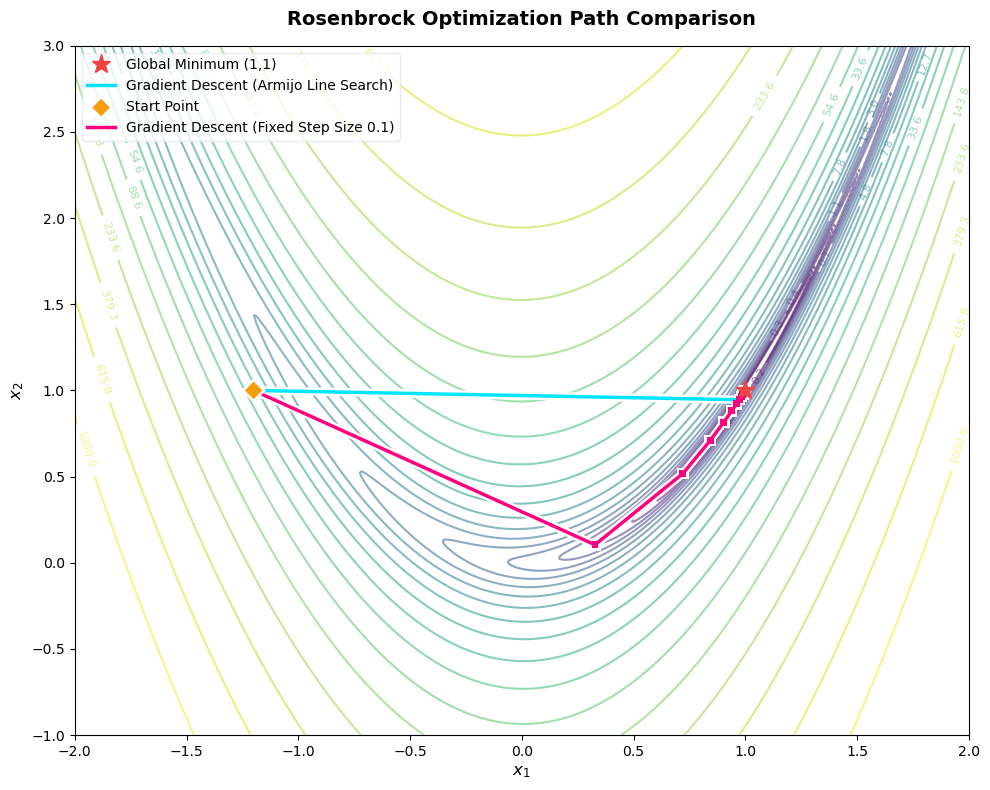

In [5]:
x0 = np.array([-1.2, 1.0])
x_line, x_noline = optimize(x0)
plot_optimization_paths(
    f=rosenbrock,
    paths=[x_line, x_noline],
    labels=['Gradient Descent (Armijo Line Search)', 'Gradient Descent (Fixed Step Size 0.1)'],
    a=a,
    b=b
)

In [6]:
print(f'Final solution with linesearch: x = {x_line[-1][0]}, y = {x_line[-1][1]}')
print(f'Gradient norm at solution with linesearch: {np.linalg.norm(grad_rosenbrock(x_line[-1]))}')
print(f'Number of iterations to converge with linesearch: {len(x_line)}')

print(f'Final solution without linesearch: x = {x_noline[-1][0]}, y = {x_noline[-1][1]}')
print(f'Gradient norm at solution without linesearch: {np.linalg.norm(grad_rosenbrock(x_noline[-1]))}')
print(f'Number of iterations to converge without linesearch: {len(x_noline)}')

Final solution with linesearch: x = 0.9999992190902652, y = 0.9999984335097669
Gradient norm at solution with linesearch: 9.833369248479482e-07
Number of iterations to converge with linesearch: 13757
Final solution without linesearch: x = 0.9998882361680524, y = 0.9997760375632542
Gradient norm at solution without linesearch: 9.997358084134586e-05
Number of iterations to converge without linesearch: 20549


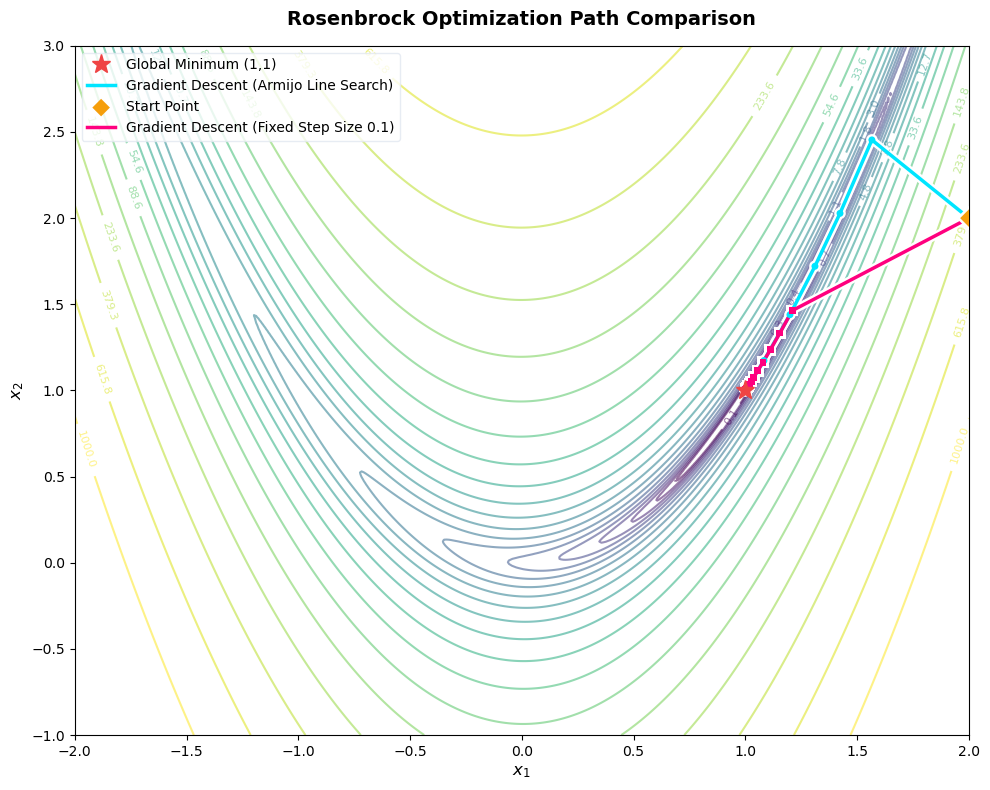

In [7]:
x0 = np.array([2.0, 2.0])
x_line, x_noline = optimize(x0)
plot_optimization_paths(
    f=rosenbrock,
    paths=[x_line, x_noline],
    labels=['Gradient Descent (Armijo Line Search)', 'Gradient Descent (Fixed Step Size 0.1)'],
    a=a,
    b=b
)

In [8]:
print(f'Final solution with linesearch: x = {x_line[-1][0]}, y = {x_line[-1][1]}')
print(f'Gradient norm at solution with linesearch: {np.linalg.norm(grad_rosenbrock(x_line[-1]))}')
print(f'Number of iterations to converge with linesearch: {len(x_line)}')

print(f'Final solution without linesearch: x = {x_noline[-1][0]}, y = {x_noline[-1][1]}')
print(f'Gradient norm at solution without linesearch: {np.linalg.norm(grad_rosenbrock(x_noline[-1]))}')
print(f'Number of iterations to converge without linesearch: {len(x_noline)}')

Final solution with linesearch: x = 1.0000007691353245, y = 1.0000015397607662
Gradient norm at solution with linesearch: 9.884220811800738e-07
Number of iterations to converge with linesearch: 17686
Final solution without linesearch: x = 1.00011179815608, y = 1.0002240561521887
Gradient norm at solution without linesearch: 9.998639986672323e-05
Number of iterations to converge without linesearch: 20744
